# FraudGuard: Dataset A (IEEE-CIS E-Commerce Fraud Detection) Pipeline
**Course**: CSET371 — Big Data Analytics and Business Intelligence  
**Institution**: Bennett University, Greater Noida  
**Team**: Harshit Pahuja, Rachit Nain, Man Mohan Gaur, Kunal Sehrawat, Bhumi Jindal  

---
### Notebook Scope
1. Ingest the raw **IEEE-CIS Fraud Detection** tables (`train_transaction.csv` + `train_identity.csv`) and execute validated `LEFT OUTER JOIN` on `TransactionID`.
2. Profile schema, missingness (`>80%` threshold + high-cardinality guard), amount statistics, categorical risk (`ProductCD`, `card4`), and hourly patterns.
3. Execute chronological leakage-free 70% / 15% / 15% train / validation / test partitioning ordered by `TransactionDT`.
4. Fit Spark ML `StringIndexer`, `OneHotEncoder`, median `Imputer`, `VectorAssembler`, and `StandardScaler` strictly on `train_df`.
5. Perform validation-split PR-AUC hyperparameter tuning and untouched held-out test benchmarking across all 5 classifiers (Logistic Regression, Random Forest, XGBoost, LightGBM, CatBoost).
6. Generate 300-DPI evaluation charts and consolidate cross-dataset + Power BI exports (`outputs/`, `powerbi/data/`).

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils.config import load_config
from src.utils.spark_utils import get_spark_session
from src.pipeline_runner import run_single_dataset, consolidate_cross_dataset_exports

config = load_config()
spark = get_spark_session(config)
print(f"Spark Version: {spark.version} | Project Root: {project_root}")

C:\Users\Harshit Pahuja\Desktop\Big_Data\.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark Version: 4.2.0 | Project Root: C:\Users\Harshit Pahuja\Desktop\Big_Data


In [2]:
# Execute Full Pipeline on Real Dataset A (IEEE-CIS E-Commerce Transactions + Identity Join)
res_a = run_single_dataset(
    spark,
    config,
    dataset_key="dataset_a",
    force_mock=False,
    dev_sample=False,
    tune_hyperparams=True,
)
consolidate_cross_dataset_exports(config, [res_a])
print(f"Dataset A completed in {res_a['runtime_seconds']}s")

2026-11-12 00:03:36,089 [INFO] ======================================================================


2026-11-12 00:03:36,089 [INFO] FRAUDGUARD PIPELINE — DATASET_A: IEEE-CIS Fraud Detection


2026-11-12 00:03:36,090 [INFO] ======================================================================


2026-11-12 00:03:36,090 [INFO] [dataset_a] Ingesting real dataset from C:\Users\Harshit Pahuja\Desktop\Big_Data\data\raw\ieee_cis\train_transaction.csv...


2026-11-12 00:03:41,307 [INFO] [dataset_a] Ingesting identity table from C:\Users\Harshit Pahuja\Desktop\Big_Data\data\raw\ieee_cis\train_identity.csv...


2026-11-12 00:03:41,785 [INFO] Validating join-key uniqueness and identity match statistics...


... (55 outputs left out)

2026-11-12 00:15:26,675 [INFO] Precision-Recall curves saved to: C:\Users\Harshit Pahuja\Desktop\Big_Data\outputs\figures\dataset_a\pr_curves.png


2026-11-12 00:15:26,680 [INFO] [dataset_a] Completed in 710.59s.


2026-11-12 00:15:27,380 [INFO] Cross-dataset comparison chart saved to: C:\Users\Harshit Pahuja\Desktop\Big_Data\outputs\figures\cross_dataset_comparison.png


Dataset A completed in 710.59s


In [3]:
# Inspect Dataset Summary, Validation Hyperparameter Tuning, Held-Out Metrics & Cost Thresholds
display(res_a["overview_df"])
display(res_a["tuning_df"])
display(res_a["results_df"][["model_name", "precision", "recall", "f1_score", "roc_auc", "pr_auc", "log_loss", "accuracy", "training_time_sec"]])
display(res_a["threshold_df"].sort_values("total_operational_cost").head(5))

,dataset_key,dataset_name,total_records,legitimate_records,fraud_records,fraud_prevalence_pct,train_records,val_records,test_records,numerical_features,categorical_features,dropped_high_null_features
0,dataset_a,IEEE-CIS Fraud Detection,590540,569877,20663,3.499,412981,88467,89092,331,24,76


,model_name,hyperparameters,val_pr_auc,val_roc_auc,val_log_loss,train_time_sec,selected,dataset_key,dataset_name
0,logistic_regression,{'reg_param': 0.001},0.3992,0.8382,0.11006,24.33,True,dataset_a,IEEE-CIS Fraud Detection
1,logistic_regression,{'reg_param': 0.01},0.3953,0.8379,0.11005,19.43,False,dataset_a,IEEE-CIS Fraud Detection
2,logistic_regression,{'reg_param': 0.1},0.3613,0.8291,0.11468,18.61,False,dataset_a,IEEE-CIS Fraud Detection
3,random_forest,"{'num_trees': 40, 'max_depth': 5}",0.3707,0.8259,0.11849,20.52,False,dataset_a,IEEE-CIS Fraud Detection
4,random_forest,"{'num_trees': 40, 'max_depth': 8}",0.4133,0.8470,0.11003,21.82,True,dataset_a,IEEE-CIS Fraud Detection
5,xgboost,"{'n_estimators': 100, 'max_depth': 4, 'learnin...",0.5051,0.8818,0.09557,9.39,False,dataset_a,IEEE-CIS Fraud Detection
6,xgboost,"{'n_estimators': 100, 'max_depth': 6, 'learnin...",0.5406,0.9035,0.09033,11.94,True,dataset_a,IEEE-CIS Fraud Detection
7,xgboost,"{'n_estimators': 100, 'max_depth': 6, 'learnin...",0.5202,0.8901,0.09360,11.68,False,dataset_a,IEEE-CIS Fraud Detection
8,lightgbm,"{'n_estimators': 100, 'max_depth': 5, 'learnin...",0.4667,0.8700,0.10100,4.38,False,dataset_a,IEEE-CIS Fraud Detection
9,lightgbm,"{'n_estimators': 100, 'max_depth': 6, 'learnin...",0.5130,0.8887,0.09416,4.53,False,dataset_a,IEEE-CIS Fraud Detection


,model_name,precision,recall,f1_score,roc_auc,pr_auc,log_loss,accuracy,training_time_sec
0,logistic_regression,0.3363,0.2325,0.2749,0.8243,0.1826,0.50123,0.9573,24.33
1,random_forest,0.8702,0.2267,0.3597,0.8468,0.4030,0.11102,0.9719,21.82
2,xgboost,0.7601,0.3205,0.4509,0.8933,0.4704,0.09912,0.9728,11.94
3,lightgbm,0.7430,0.3176,0.4450,0.8885,0.4718,0.09927,0.9724,3.96
4,catboost,0.8101,0.2953,0.4328,0.8744,0.4705,0.10041,0.9730,7.77


,threshold,precision,recall,f1_score,true_positives,false_positives,true_negatives,false_negatives,flagged_volume,alert_rate_pct,total_operational_cost,dataset_key,dataset_name,model_name
0,0.05,0.1985,0.7021,0.3095,2180,8805,77182,925,10985,12.33,550550.0,dataset_a,IEEE-CIS Fraud Detection,lightgbm
1,0.10,0.2949,0.5710,0.3889,1773,4240,81747,1332,6013,6.75,708400.0,dataset_a,IEEE-CIS Fraud Detection,lightgbm
2,0.15,0.3471,0.4931,0.4074,1531,2880,83107,1574,4411,4.95,815800.0,dataset_a,IEEE-CIS Fraud Detection,lightgbm
3,0.20,0.3793,0.4525,0.4127,1405,2299,83688,1700,3704,4.16,872990.0,dataset_a,IEEE-CIS Fraud Detection,lightgbm
4,0.25,0.4932,0.4193,0.4533,1302,1338,84649,1803,2640,2.96,914880.0,dataset_a,IEEE-CIS Fraud Detection,lightgbm


eda_overview.png


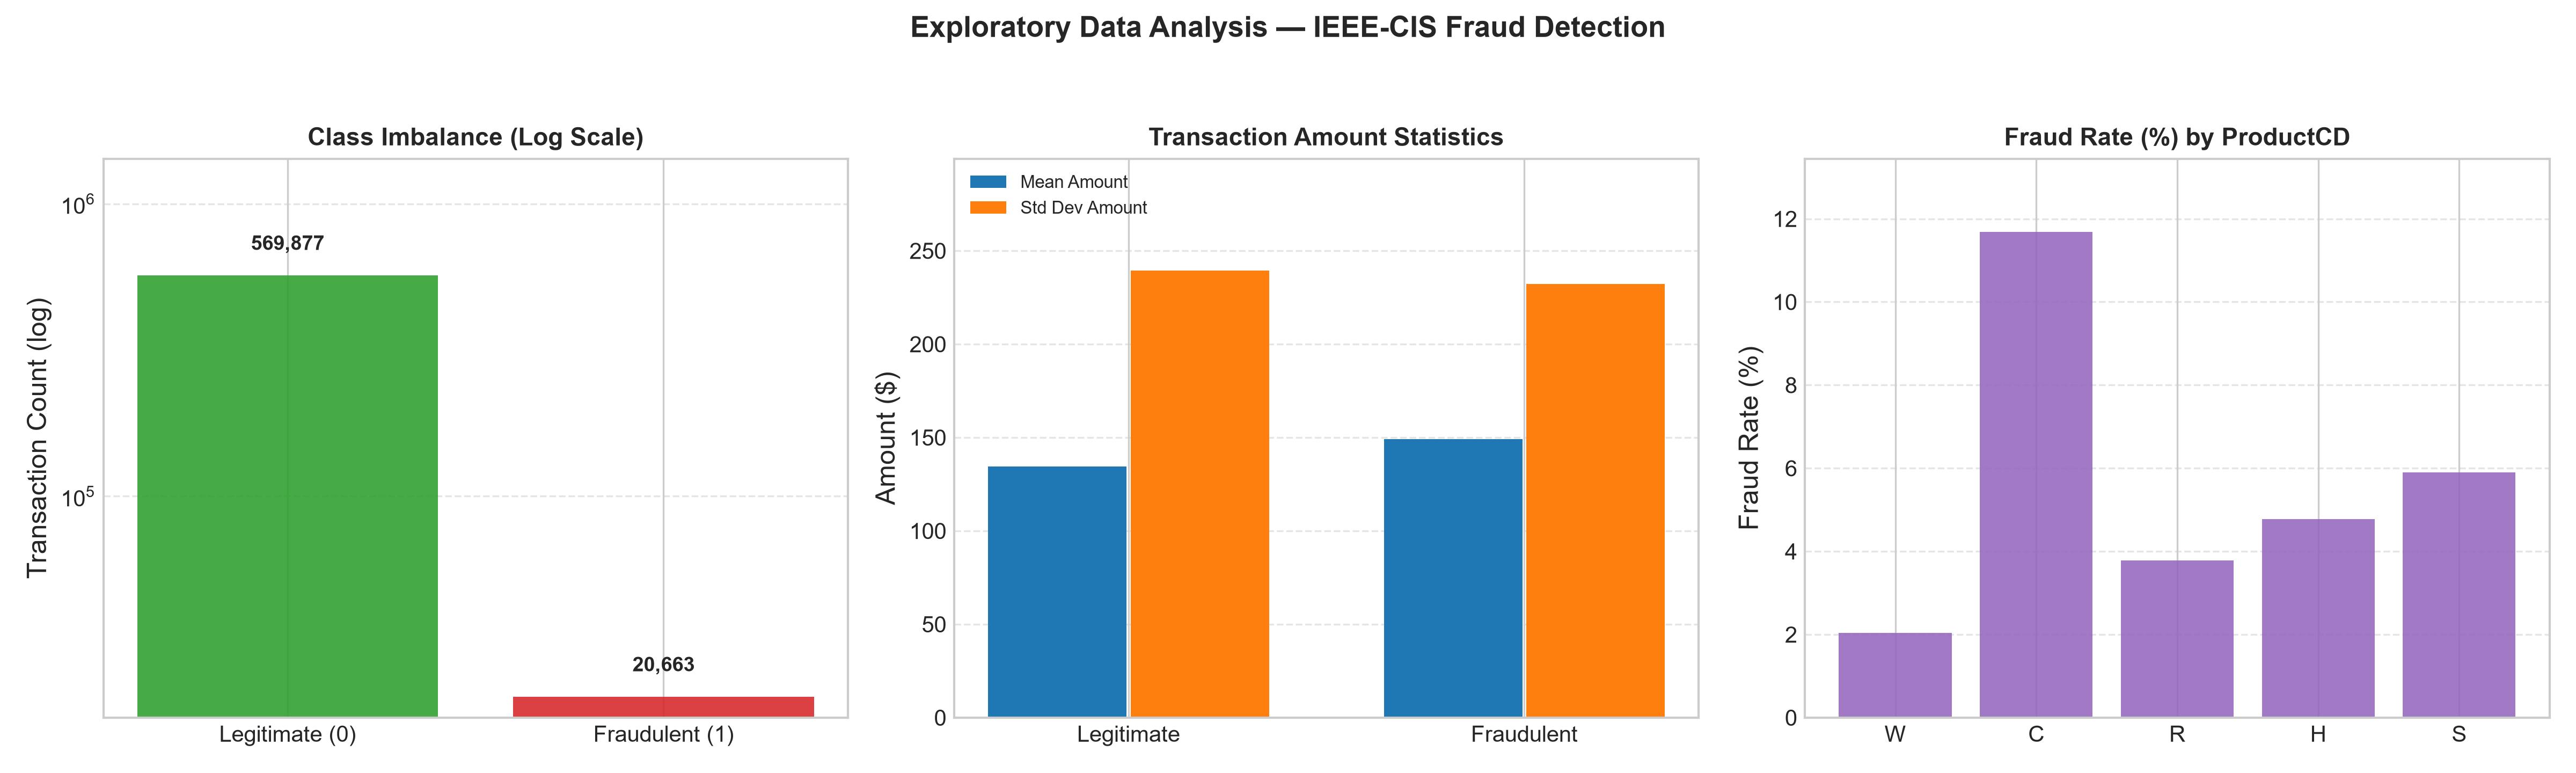

model_comparison_bar_chart.png


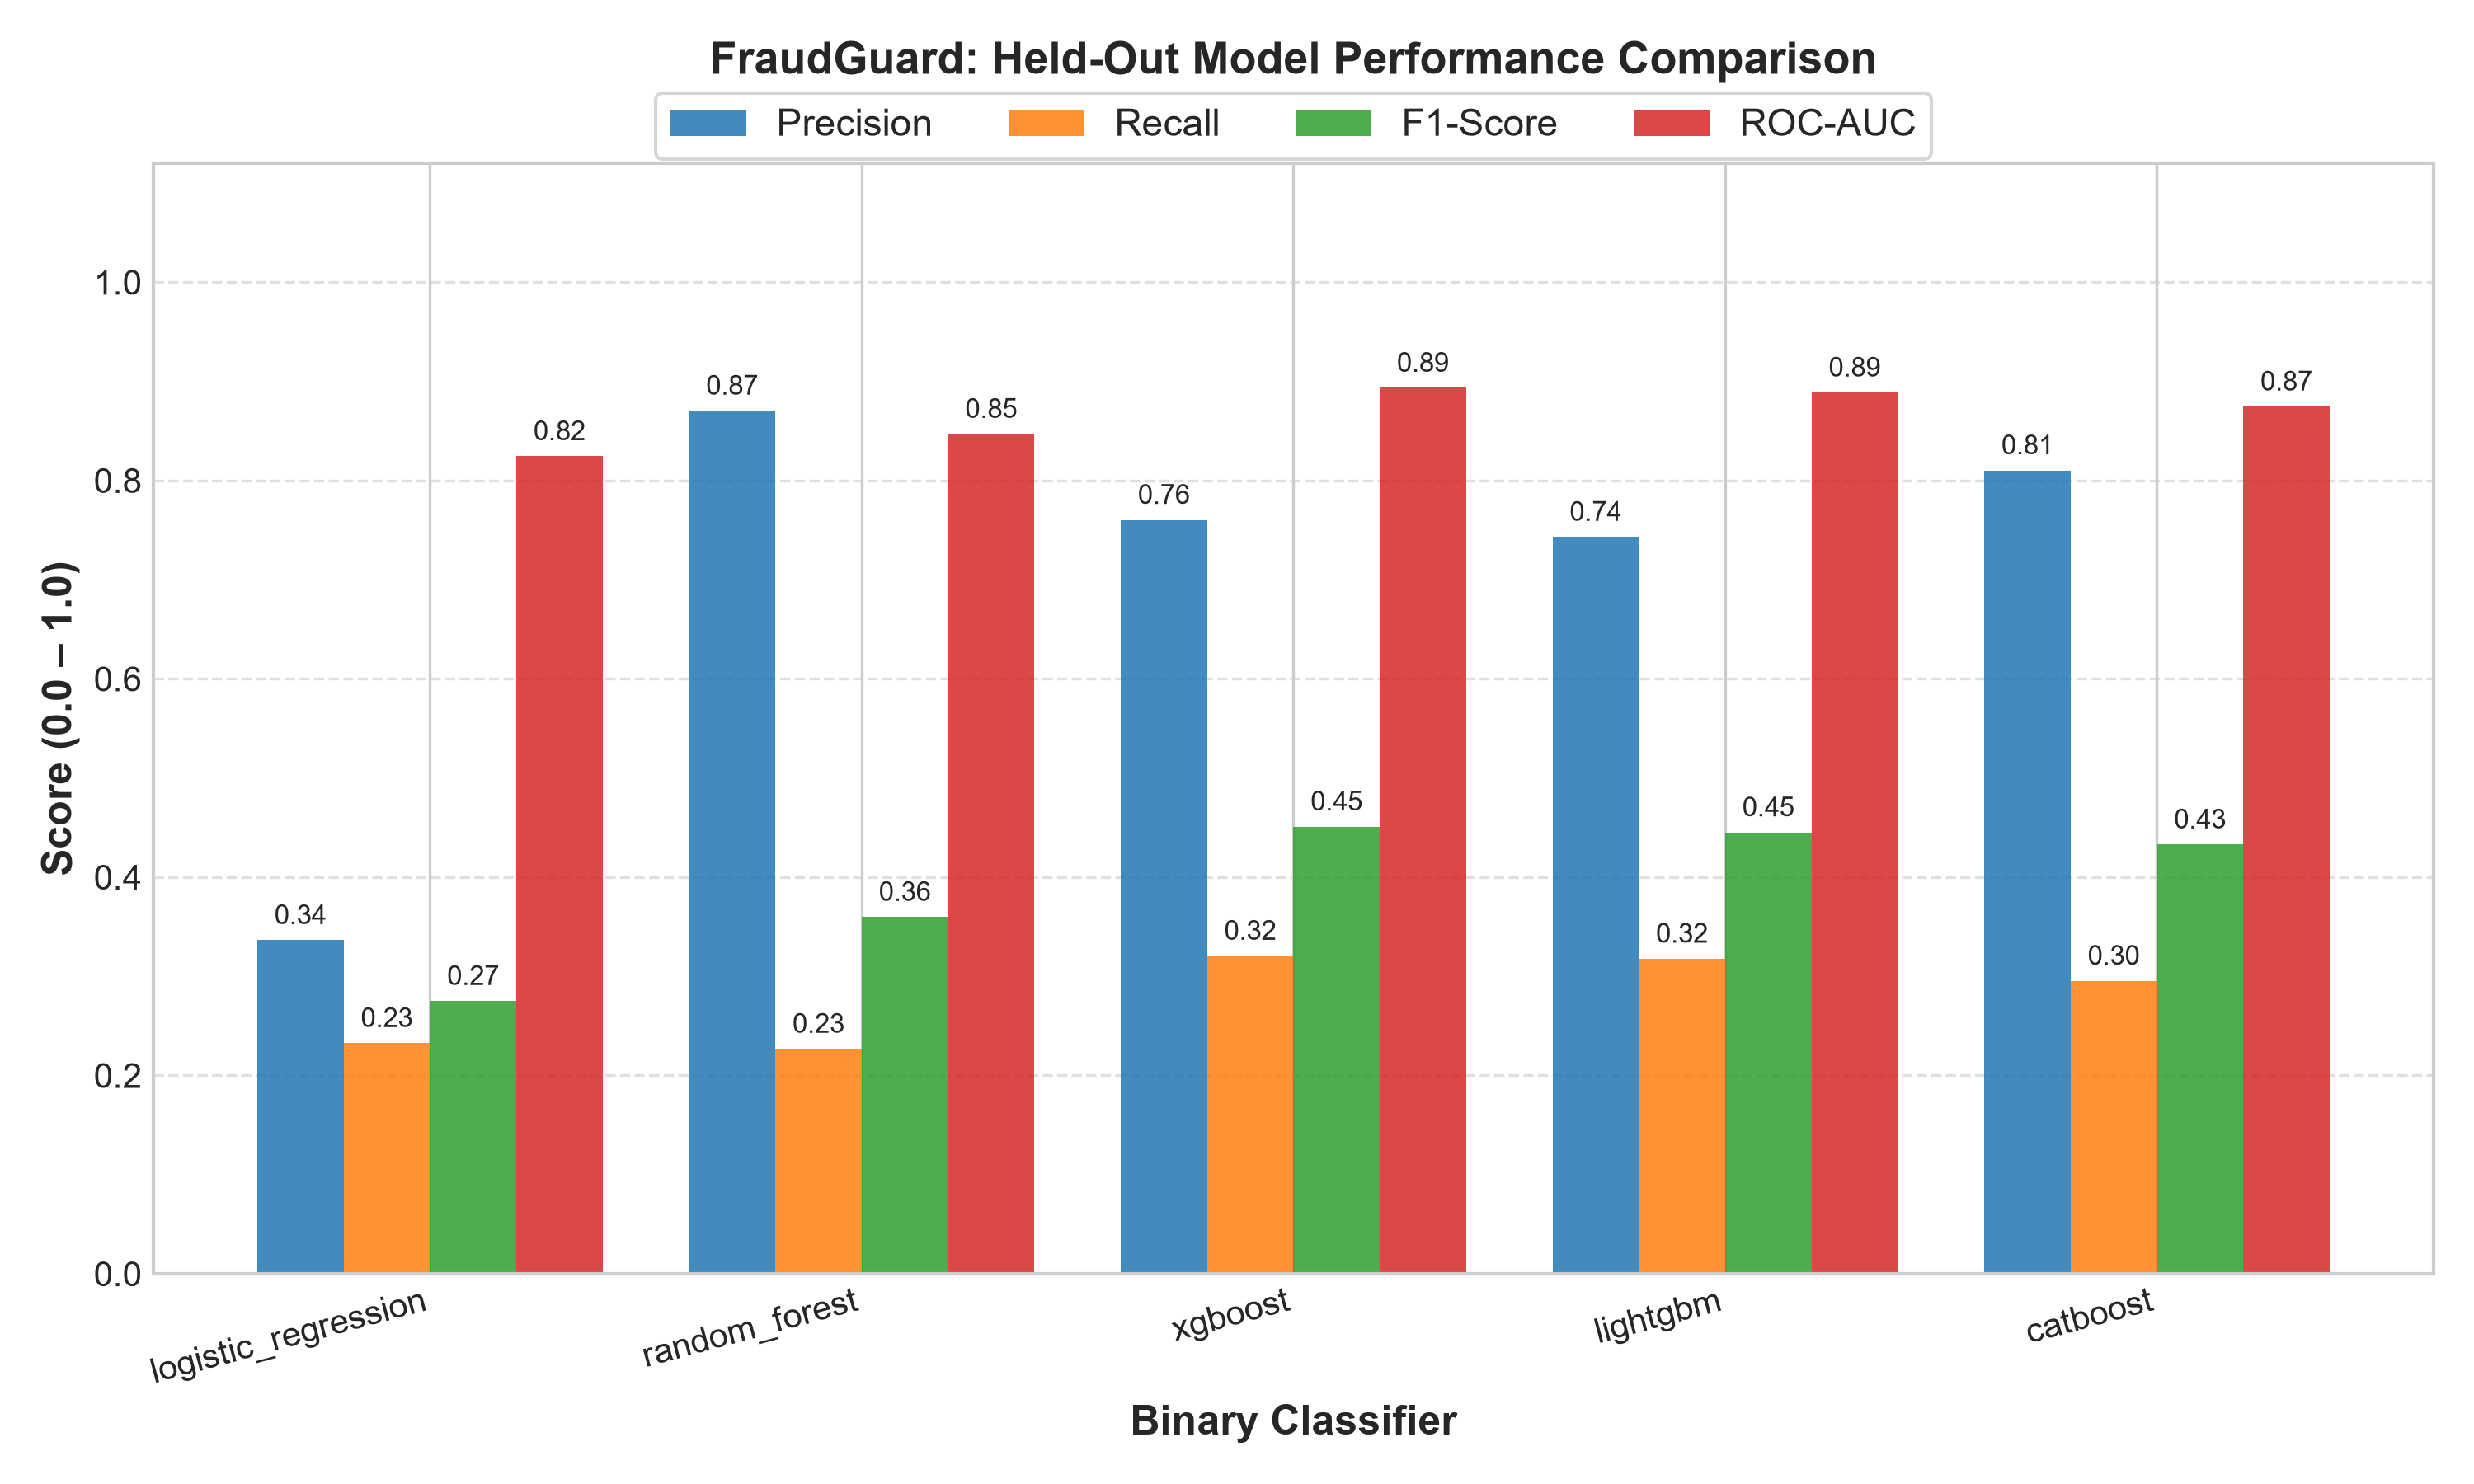

roc_curves.png


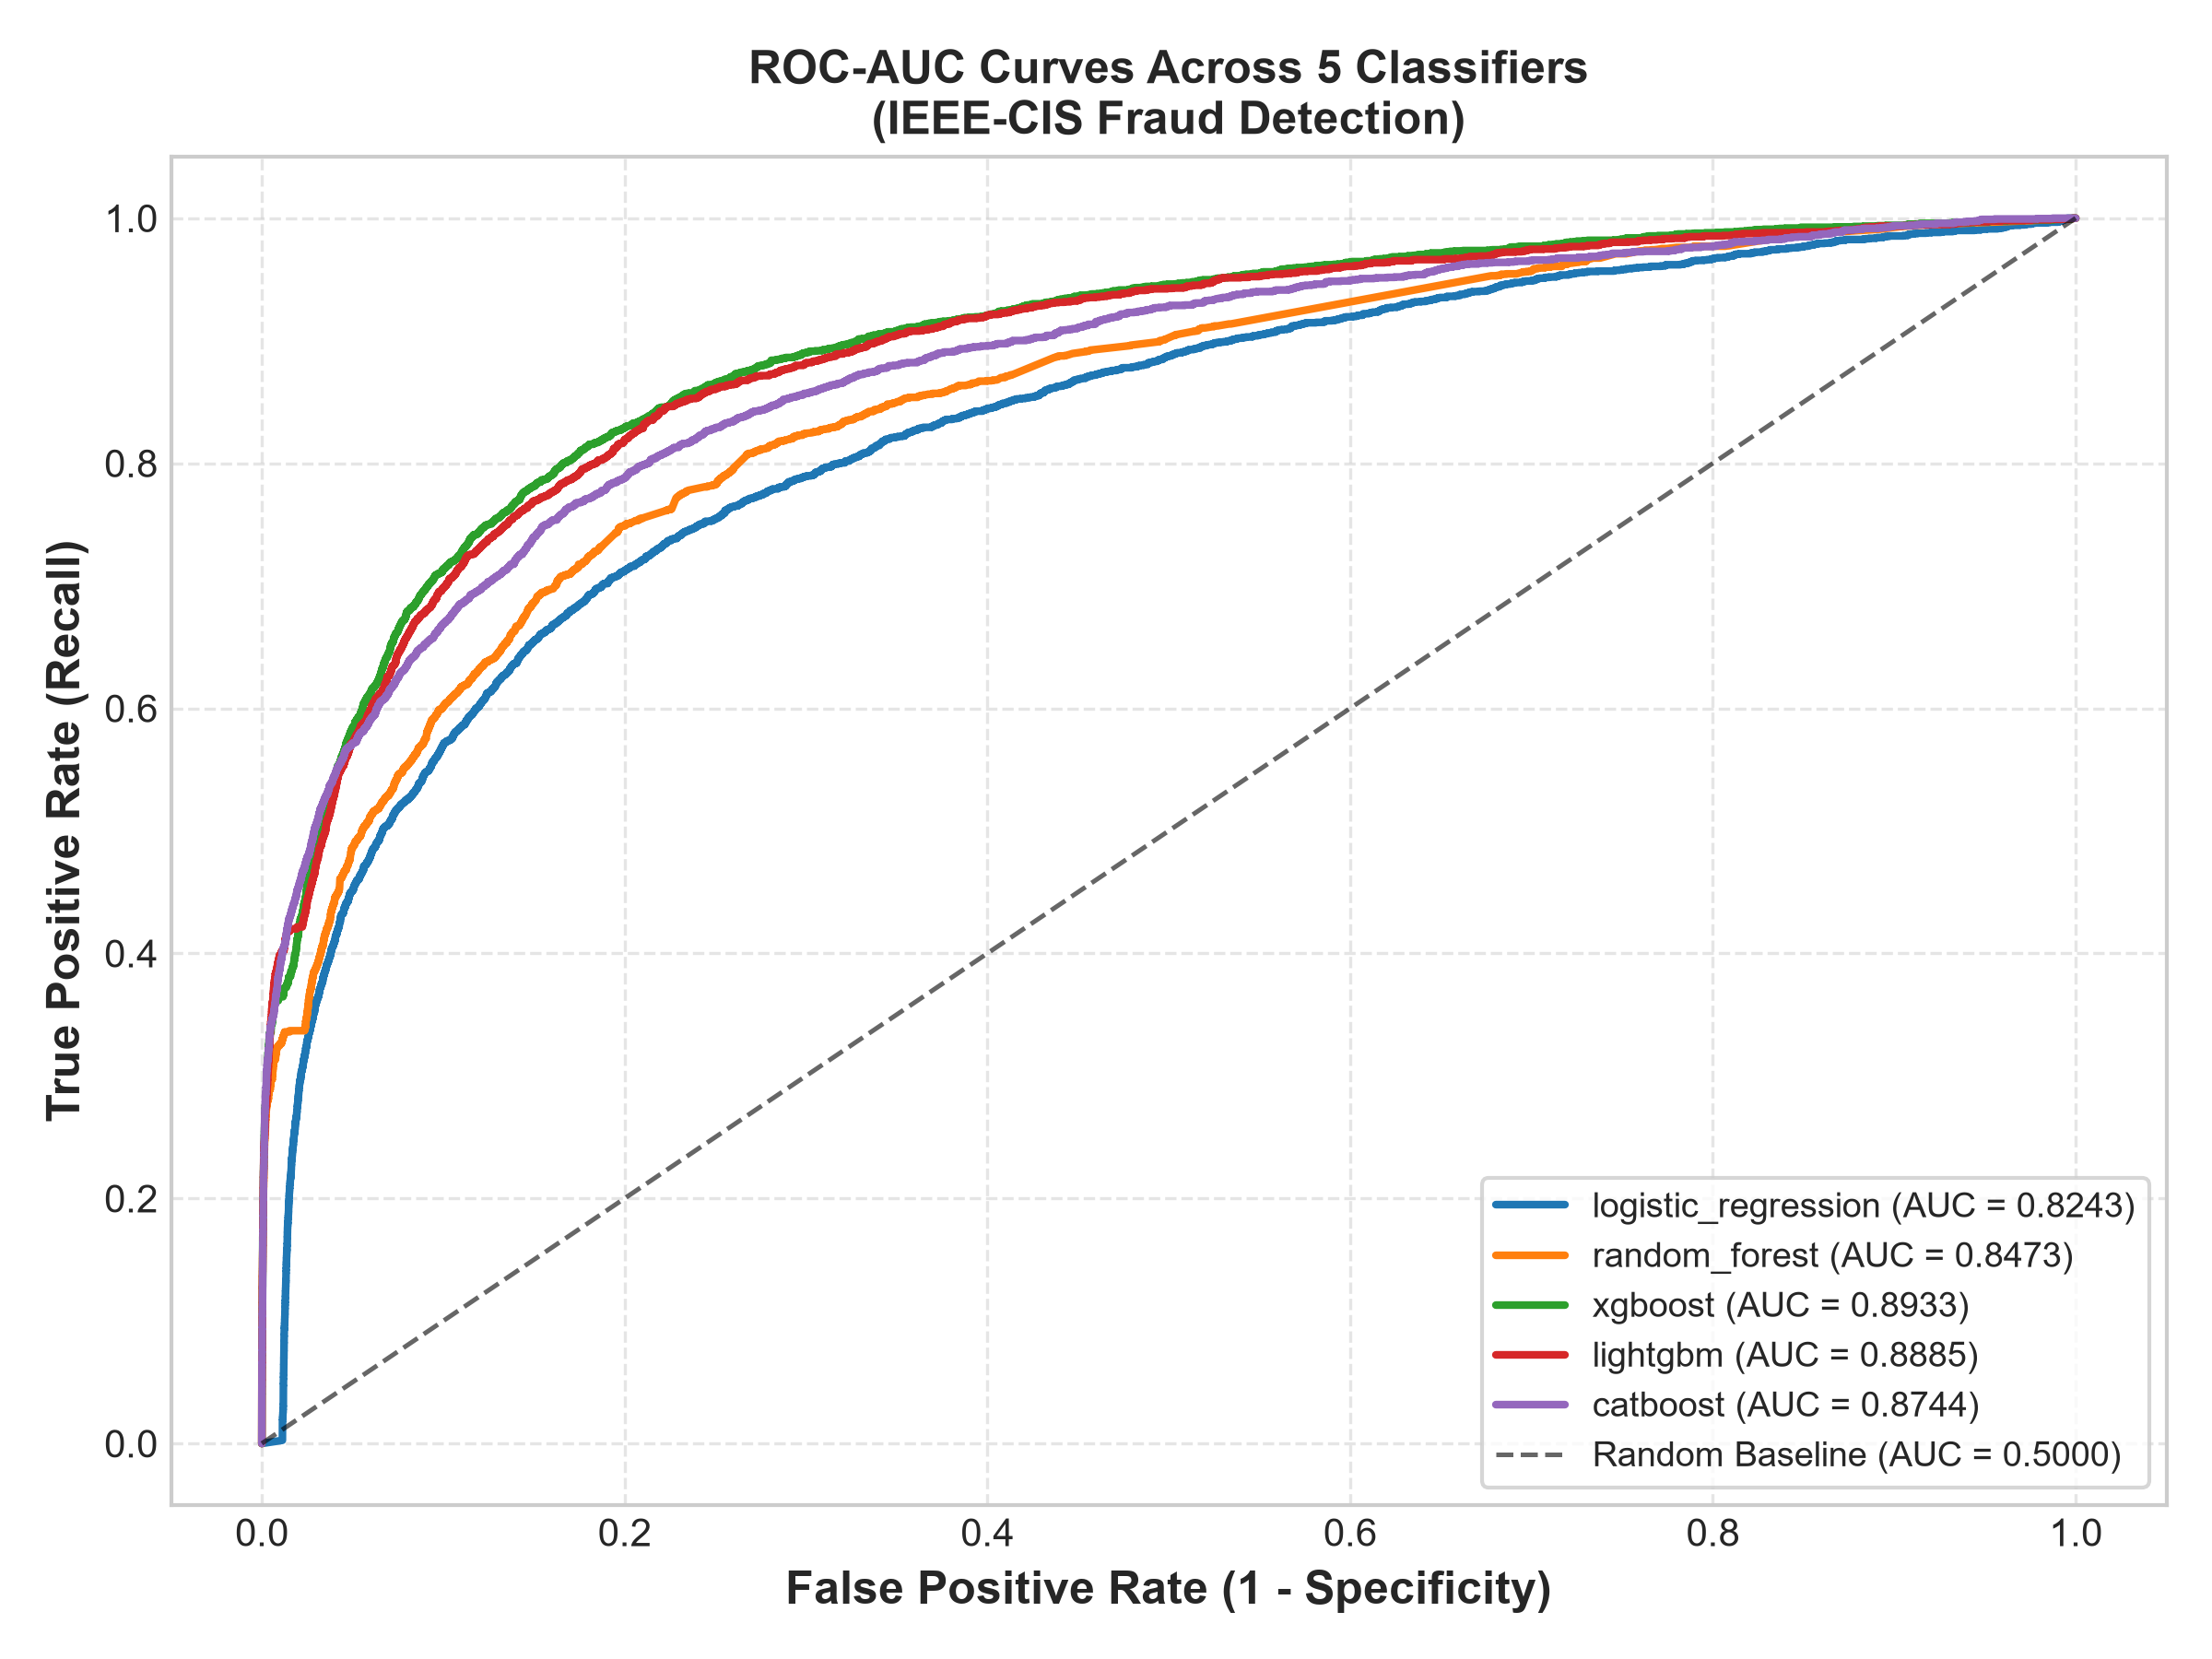

pr_curves.png


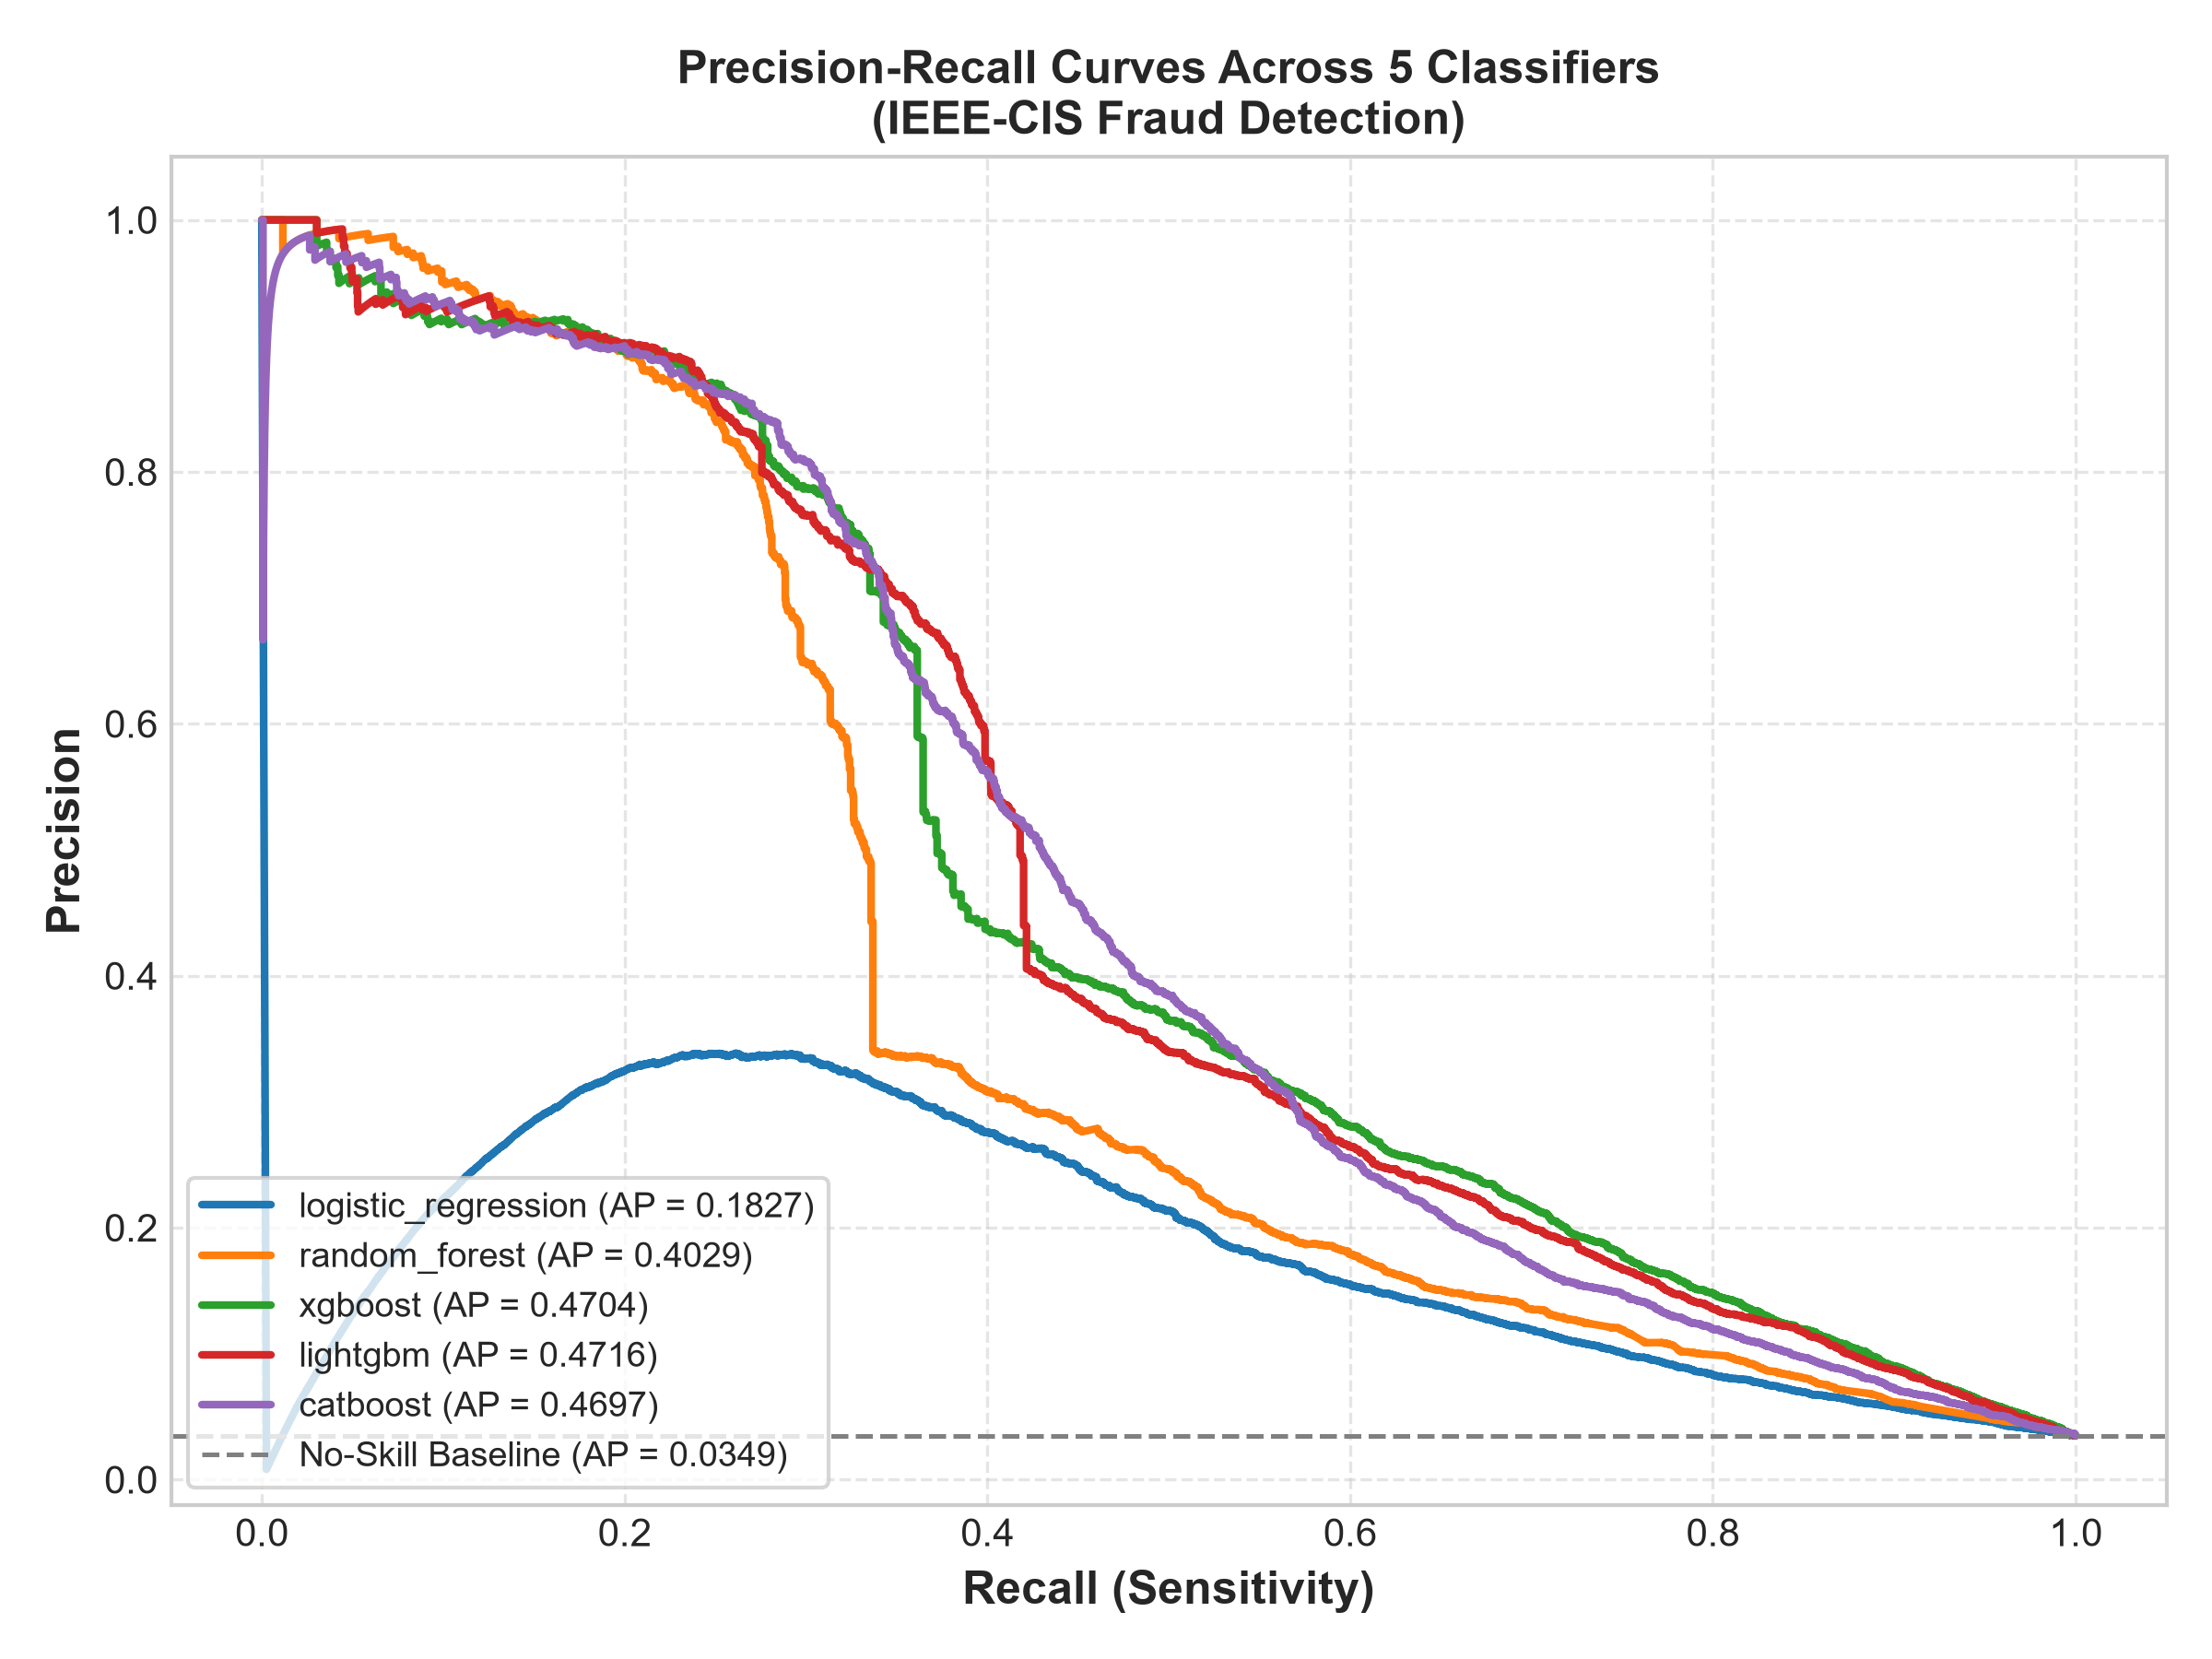

confusion_matrices_grid.png


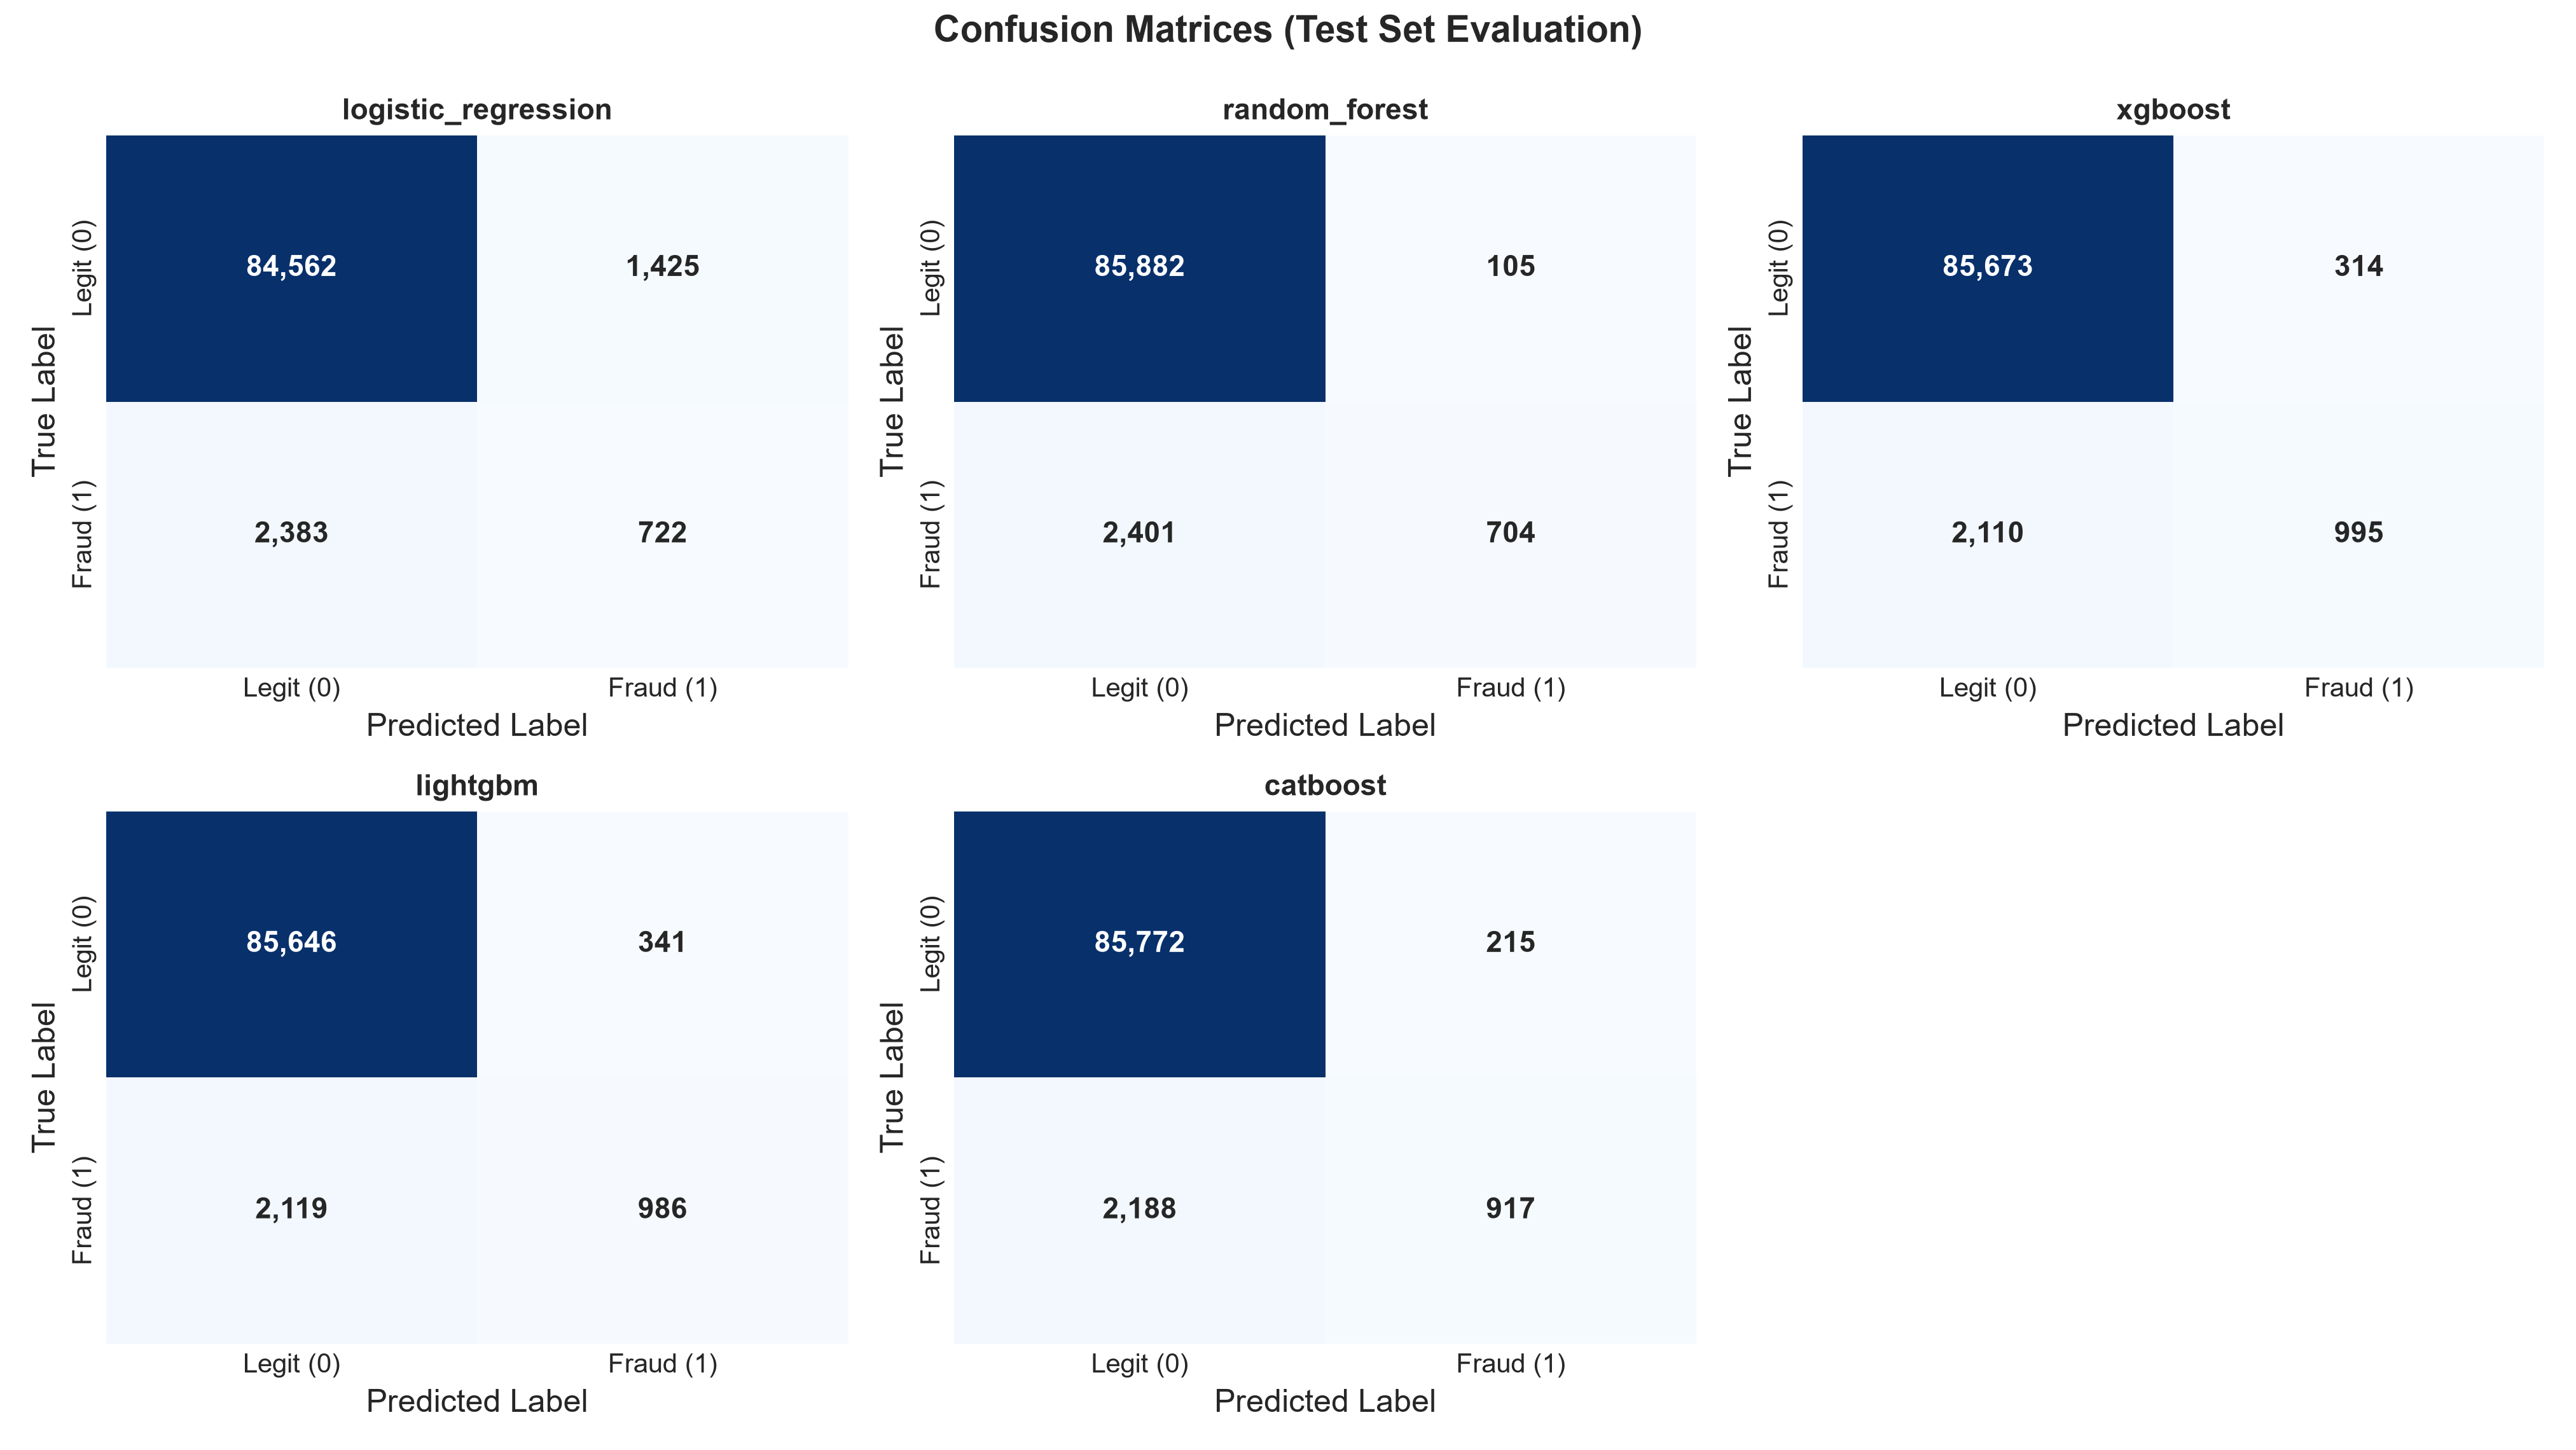

threshold_tradeoffs.png


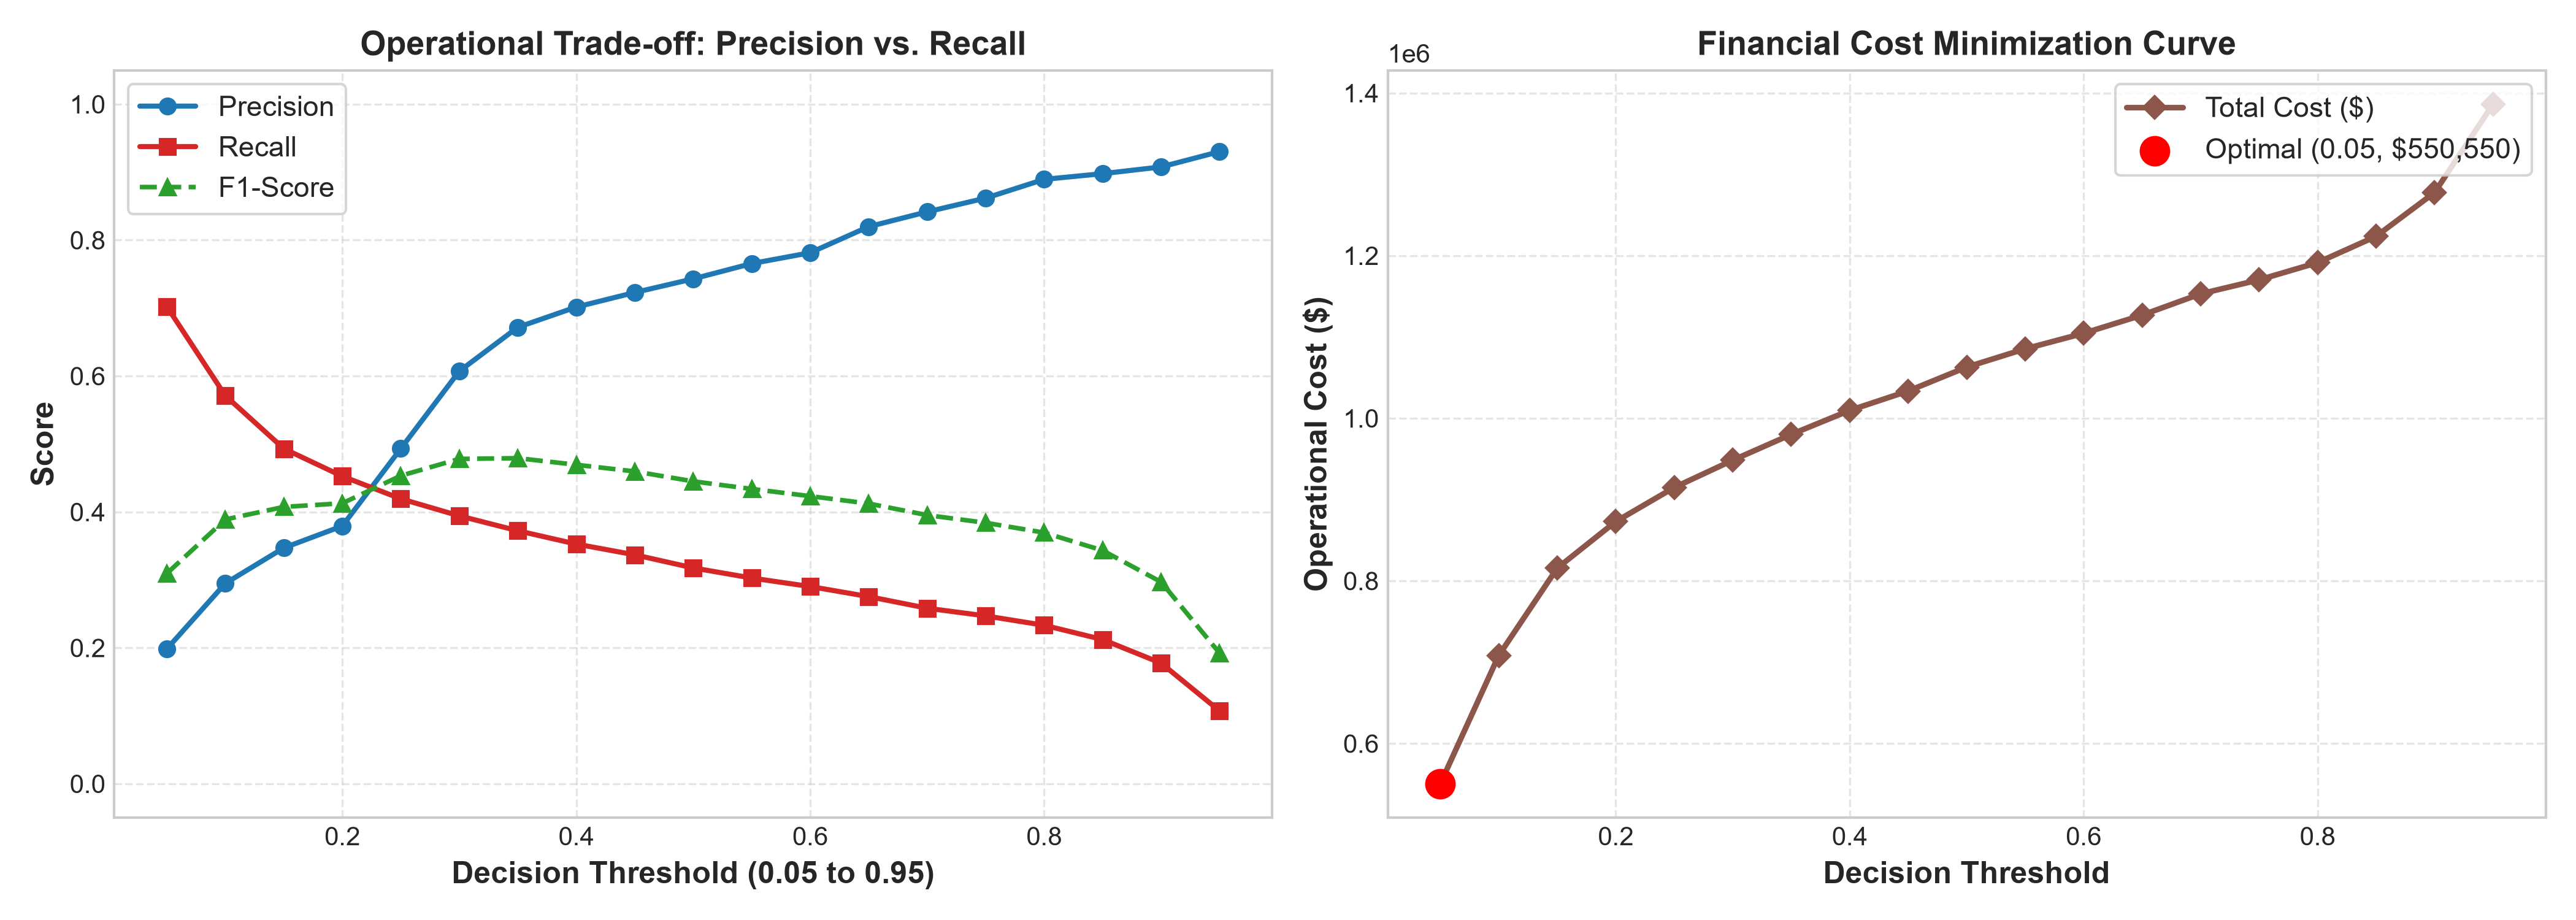

cross_dataset_comparison.png


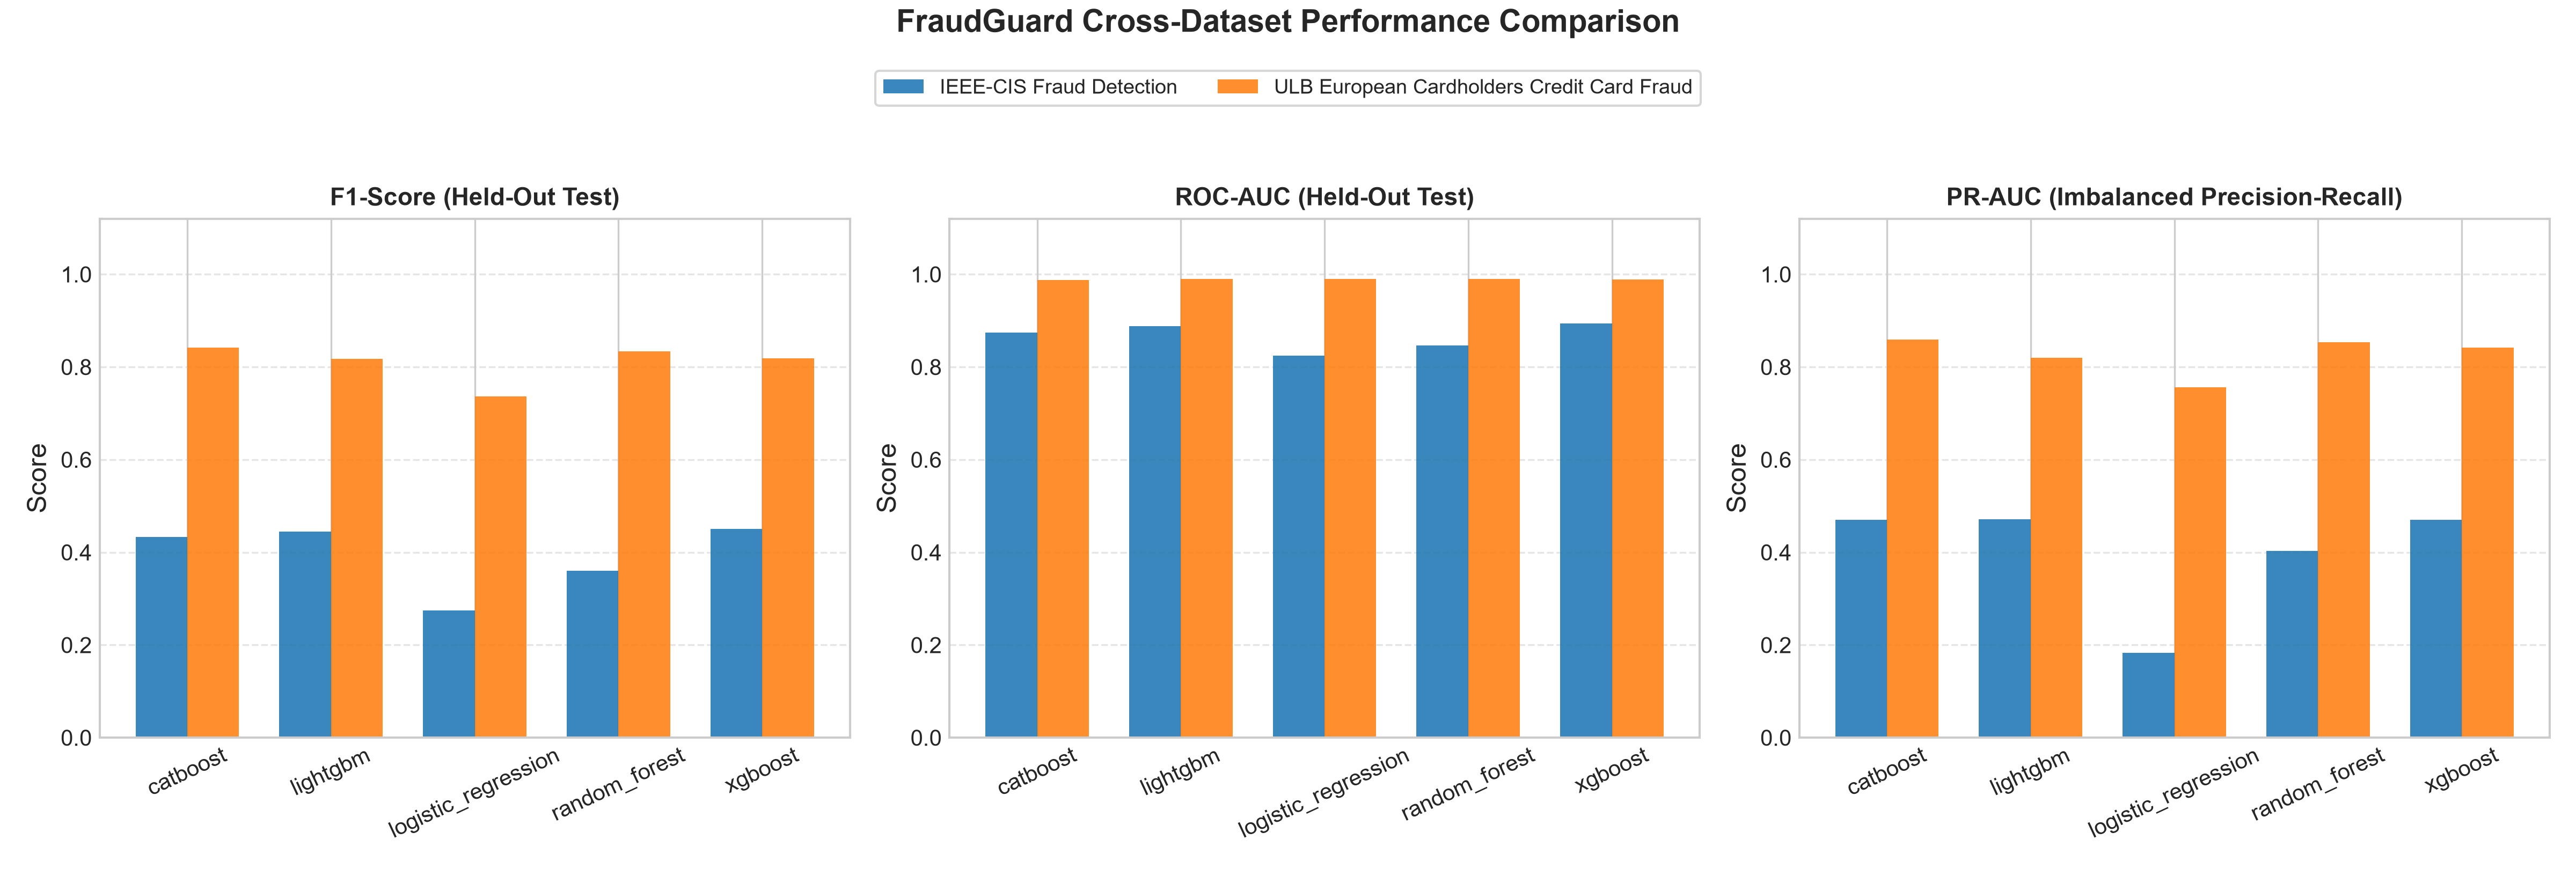

In [4]:
# Display Dataset A & Cross-Dataset Evaluation Figures
fig_dir = project_root / "outputs" / "figures" / "dataset_a"
for fname in [
    "eda_overview.png",
    "model_comparison_bar_chart.png",
    "roc_curves.png",
    "pr_curves.png",
    "confusion_matrices_grid.png",
    "threshold_tradeoffs.png",
]:
    fp = fig_dir / fname
    if fp.exists():
        print(fname)
        display(Image(filename=str(fp)))

cross_fig = project_root / "outputs" / "figures" / "cross_dataset_comparison.png"
if cross_fig.exists():
    print("cross_dataset_comparison.png")
    display(Image(filename=str(cross_fig)))

spark.stop()